# Comparing HTFA kernels on real multi-subject fMRI

We fit the same three adults watching *Partly Cloudy* from `development_fmri` with all three kernels, each with one or two components per factor. This is a small, reproducible example of which candidate reconstructs **this dataset** best, not a population benchmark.

K=15, the same subjects, preprocessing, all 168 frames and full voxel masks are used throughout. We try two starts per candidate, selecting by full-data RSS. Optimization uses 3000 voxels per subject; scoring uses every voxel. Candidate runtime and convergence are recorded. More components enlarge the model class, but local optimization and regularization need not produce monotonically improving fits.

The AIC/AICc/BIC values below use the **nominal conditional Gaussian** convention explained in Tutorial 14; they are not hierarchical marginal likelihoods. Real fMRI violates independent residual assumptions. The complete run refits locally and may take several minutes; downloading is cached.

In [2]:
# Install htfa from PyPI if needed (for example on Colab).
try:
    import htfa  # noqa: F401
except ImportError:
    %pip install -q htfa

In [3]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import htfa
from htfa.io import Subject
from htfa.stats import parameter_count, reconstruction_statistics
from htfa.tfa import standardize_data

data = htfa.datasets.fetch_development_fmri(n_subjects=3)
subjects = [Subject(x, r) for x, r in zip(data.data, data.coords, strict=True)]
print("Subjects:", data.subject_ids)
print("Shapes:", [x.shape for x in data.data])
settings = dict(
    K=15,
    template_update="fixed",
    max_global_iter=25,
    max_voxels=3000,
    init="ncorr",
    n_jobs=3,
)
print(settings)

Subjects: ['sub-pixar123', 'sub-pixar124', 'sub-pixar125']
Shapes: [(25079, 168), (23726, 168), (26739, 168)]
{'K': 15, 'template_update': 'fixed', 'max_global_iter': 25, 'max_voxels': 3000, 'init': 'ncorr', 'n_jobs': 3}


In [4]:
records, results, attempts = [], {}, []
for kernel in ("rbf", "laplace", "mexican_hat"):
    for components in (1, 2):
        label = f"{kernel}, M={components}"
        best = None
        started = time.perf_counter()
        for seed in (0, 1):
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                model = htfa.HTFA(
                    **settings,
                    kernel=kernel,
                    n_components=components,
                    random_state=seed,
                ).fit(data.data, data.coords)
            result = htfa.HTFAResults(model, subjects)
            score = reconstruction_statistics(result)
            attempts.append(
                dict(
                    candidate=label,
                    seed=seed,
                    rss=score.rss,
                    iterations=model.n_iter_,
                    reason=model.converged_reason_,
                    warnings="; ".join(str(w.message) for w in caught),
                )
            )
            if best is None or score.rss < best[0].rss:
                best = score, result, seed
        score, result, seed = best
        results[label] = result
        records.append(
            dict(
                candidate=label,
                seed=seed,
                seconds=time.perf_counter() - started,
                **parameter_count(result),
                **score.to_dict(),
            )
        )
        print(label, "R²", round(score.r2, 4), "BIC", round(score.bic), flush=True)
table = pd.DataFrame(records).set_index("candidate")
for name in ("aic", "aicc", "bic"):
    table["delta_" + name] = table[name] - table[name].min()
table[
    [
        "r2",
        "spatial",
        "temporal",
        "n_parameters",
        "delta_aic",
        "delta_aicc",
        "delta_bic",
        "seconds",
    ]
]

rbf, M=1 R² 0.0541 BIC 35437009


rbf, M=2 R² 0.0573 BIC 35398391


laplace, M=1 R² 0.0531 BIC 35450219


laplace, M=2 R² 0.0562 BIC 35413071


mexican_hat, M=1 R² 0.0538 BIC 35440961


mexican_hat, M=2 R² 0.0568 BIC 35405264


,r2,spatial,temporal,n_parameters,delta_aic,delta_aicc,delta_bic,seconds
candidate,,,,,,,,
"rbf, M=1",0.054125,180,7560,7741,41847.430115,41846.872638,38617.232347,11.833752
"rbf, M=2",0.057273,405,7560,7966,0.000000,0.000000,0.000000,44.885226
"laplace, M=1",0.053140,180,7560,7741,55058.199472,55057.641994,51828.001703,15.885609
"laplace, M=2",0.056182,405,7560,7966,14679.207184,14679.207184,14679.207184,48.654703
"mexican_hat, M=1",0.053831,180,7560,7741,45799.958603,45799.401125,42569.760835,14.093508
"mexican_hat, M=2",0.056762,405,7560,7966,6872.209722,6872.209722,6872.209722,44.226368


## Fit quality and penalty

R² favors smaller residuals; ΔIC is relative to the best candidate under each criterion (zero is best). Temporal parameter counts are identical because K and T are fixed, while component counts change the spatial budget. A large ΔBIC here is not calibrated evidence under residual dependence.

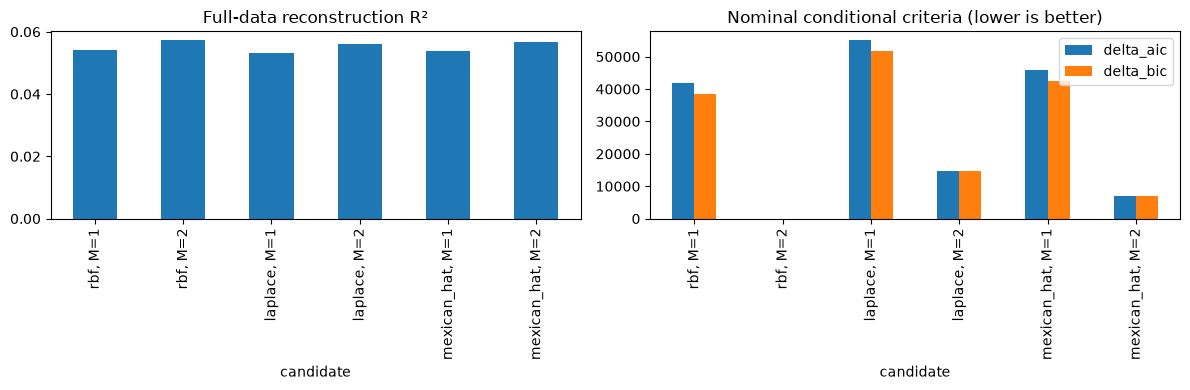

Highest R²: rbf, M=2
Lowest nominal AIC: rbf, M=2
Lowest nominal BIC: rbf, M=2


,candidate,seed,rss,iterations,reason
0,"rbf, M=1",0,1.200865e+07,7,plateau
1,"rbf, M=1",1,1.200446e+07,6,threshold
2,"rbf, M=2",0,1.196899e+07,9,plateau
3,"rbf, M=2",1,1.196452e+07,13,plateau
4,"laplace, M=1",0,1.201780e+07,8,plateau
5,"laplace, M=1",1,1.201697e+07,8,plateau
6,"laplace, M=2",0,1.197955e+07,8,plateau
7,"laplace, M=2",1,1.197837e+07,7,plateau
8,"mexican_hat, M=1",0,1.200820e+07,11,plateau
9,"mexican_hat, M=1",1,1.201406e+07,6,plateau


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
table.r2.plot.bar(ax=axes[0], title="Full-data reconstruction R²")
table[["delta_aic", "delta_bic"]].plot.bar(
    ax=axes[1], title="Nominal conditional criteria (lower is better)"
)
plt.tight_layout()
plt.show()
print("Highest R²:", table.r2.idxmax())
print("Lowest nominal AIC:", table.aic.idxmin())
print("Lowest nominal BIC:", table.bic.idxmin())
pd.DataFrame(attempts)[["candidate", "seed", "rss", "iterations", "reason"]]

## Example reconstructed frames

The examples use subject 0 at frames 30, 80 and 130. Each row uses the same axial slice nearest MNI z=0. Every panel shares the same symmetric scale in voxel-standardized units, including the observed frames; no reconstruction is independently rescaled. Outside-mask locations are blank. These examples show spatial reconstruction, not forecast accuracy.

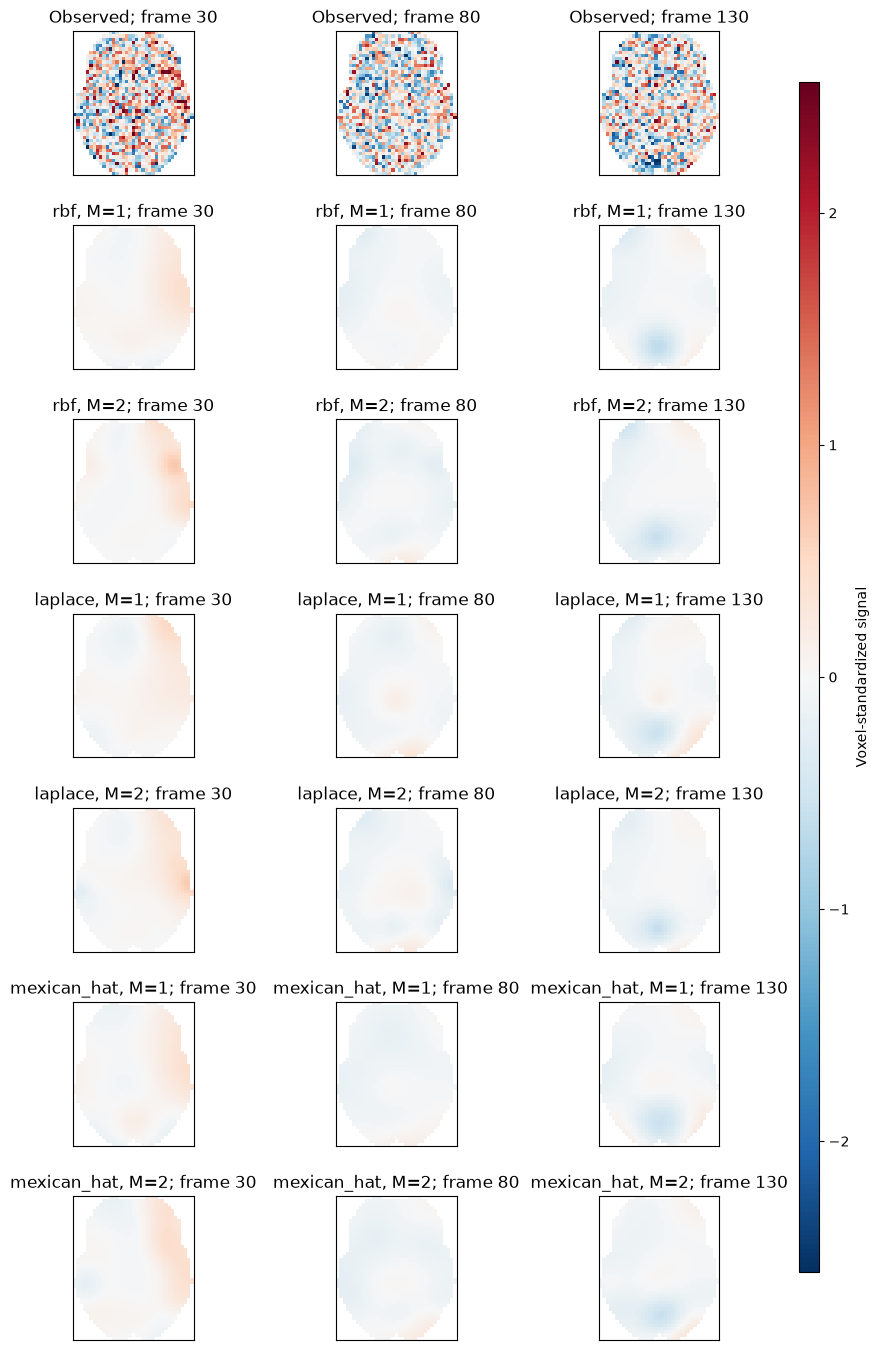

In [6]:
frames = [30, 80, 130]
coords = data.coords[0]
z = np.unique(coords[:, 2])[np.argmin(abs(np.unique(coords[:, 2])))]
keep = coords[:, 2] == z
xx, ix = np.unique(coords[keep, 0], return_inverse=True)
yy, iy = np.unique(coords[keep, 1], return_inverse=True)
observed = standardize_data(data.data[0], True)
arrays = {
    "Observed": observed,
    **{name: res.reconstruct(0) for name, res in results.items()},
}
limit = np.percentile(abs(observed[keep][:, frames]), 99)
fig, axes = plt.subplots(len(arrays), len(frames), figsize=(10, 17))
for row, (label, values) in enumerate(arrays.items()):
    for col, frame in enumerate(frames):
        plane = np.full((len(yy), len(xx)), np.nan)
        plane[iy, ix] = values[keep, frame]
        im = axes[row, col].imshow(
            plane,
            origin="lower",
            cmap="RdBu_r",
            vmin=-limit,
            vmax=limit,
            extent=[xx.min(), xx.max(), yy.min(), yy.max()],
        )
        axes[row, col].set_title(f"{label}; frame {frame}")
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
fig.subplots_adjust(right=0.87, hspace=0.35)
fig.colorbar(
    im, cax=fig.add_axes([0.9, 0.15, 0.02, 0.7]), label="Voxel-standardized signal"
)
plt.show()

## Scope of the conclusion

The printed winners answer a descriptive question about these three participants, K=15 and this optimization budget. A penalized winner can differ from the R² winner. The figures expose what additional components capture rather than treating a scalar rank as the whole result. Check the start/convergence table before interpreting small differences; reaching the iteration limit is not proof of an optimum.

This comparison is in-sample and uses full-run preprocessing. It does not establish held-out performance, independent-subject generalization or a universally best kernel. A subsequent blocked validation study should refit preprocessing and HTFA within each training split and keep the evaluation mask identical across candidates.

### Reading the results

The printed table identifies the best candidate under R² and each nominal information criterion. Inspect the differences across starts and their convergence reasons alongside the scores. More mixture parameters increase the complexity penalty; the residual reduction determines whether a mixture ranks above its single-component counterpart. Continuing a regularized hierarchical fit need not decrease full-data RSS monotonically because the optimization objective includes priors. Correlated residuals mean that large ΔIC magnitudes do not imply calibrated certainty.
